# Time-aware · 01 — Feature selection

Every decision here is made with this strategy's own validation scheme: **forward chaining**. Each fold trains on the past and validates on the block that follows; the last 5 days of the training block are the early-stopping (ES) rows. Validation rows only score models; stability and importance are measured on ES rows.

| Fold | Validation block | ES rows | Fit rows |
|---|---|---|---|
| 1 | 1 – 14 Sep | 27 – 31 Aug | before 27 Aug |
| 2 | 15 – 30 Sep | 10 – 14 Sep | before 10 Sep |
| 3 | 1 – 11 Oct | 26 – 30 Sep | before 26 Sep |
| 4 | 12 – 22 Oct | 7 – 11 Oct | before 7 Oct |

| § | Step |
|---|---|
| 1 | Folds |
| 2 | Debiased Information Value and the three filters (floor, stability, redundancy) |
| 3 | LightGBM, then CatBoost: score every configuration, importance, selection rule |
| 4 | Save `selection.json` |

**Selection rule (paired, capped one-SE).** Best = highest mean fold AUC. Configuration *c* qualifies if its mean paired difference to the best is ≥ −min(SE, 0.002); the qualifying configuration with the fewest features is chosen (tie: higher mean AUC). Every configuration, `C_all` included, is eligible. With four folds the SE rests on three degrees of freedom.

> Runtime: about 11 configurations × 4 folds per family, selection mode.

In [1]:
import gc
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lightgbm as lgb
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import roc_auc_score

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)

# ========================================= Settings =========================================
STRATEGY = 'time_cv'
SEED = 42

LGBM_PARAMS = dict(
    n_estimators=2000, learning_rate=0.03, num_leaves=31, min_child_samples=100,
    reg_lambda=1.0, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    metric='auc', random_state=SEED, n_jobs=max(1, os.cpu_count() // 2), verbose=-1,
)
LGBM_ES_ROUNDS = 100                      # lgb.early_stopping(100, verbose=False)

CATBOOST_PARAMS = dict(
    iterations=3000, learning_rate=0.05, depth=6, l2_leaf_reg=3.0,
    loss_function='Logloss', eval_metric='AUC', border_count=254,
    random_seed=SEED, allow_writing_files=False, verbose=0,
    task_type='GPU',                      # CatBoost is run explicitly on the GPU
)
CATBOOST_ES_ROUNDS = 200

RARE_MIN_COUNT = 100        # categorical levels with fewer rows are pooled
RARE_CODE = -1
UNSEEN_CODE = -2
IV_FLOOR = 0.005
IV_C02 = 0.02
STABILITY_MIN = 0.5
STABILITY_IV_MIN = 0.001    # folds with IV_fit below this are ignored in the stability mean
CORR_MAX = 0.85
SE_CAP = 0.002              # cap on the paired SE in the selection rule
TOP_K = [30, 26, 22, 18, 15, 12, 10, 8]
PERM_ROWS = 6000
PERM_REPEATS = 3
# ============================================================================================

In [2]:
DATA = Path('../Data/Processed_time_cv')
TARGET, ID_COL, DATE_COL = 'loan_default', 'UniqueID', 'disb_date'

manifest = json.loads((DATA / 'manifest.json').read_text())
NUMERIC = manifest['numeric_columns']
CATEGORICAL = manifest['categorical_columns']
CANDIDATES = NUMERIC + CATEGORICAL


def encode_categoricals(df: pd.DataFrame) -> None:
    """In place: raw values -> integer codes from the manifest maps (index in the list = code); unseen -> -2."""
    for col in CATEGORICAL:
        lookup = {v: i for i, v in enumerate(manifest['category_maps'][col])}
        df[col] = df[col].astype(str).map(lookup).fillna(UNSEEN_CODE).astype('int32')


data = pd.read_csv(DATA / 'train_features.csv', parse_dates=[DATE_COL])
encode_categoricals(data)
for col in NUMERIC:
    if data[col].dtype == 'float64':
        data[col] = data[col].astype('float32')

y = data[TARGET].to_numpy()
dates = data[DATE_COL]
XALL = data[CANDIDATES]
print(f'train: {data.shape}  default rate {y.mean():.4f}')


def ordered(feats):
    """Features in candidate order (column order of every model matrix)."""
    keep = set(feats)
    return [c for c in CANDIDATES if c in keep]


# --------------------------------------------------------------------------- pooling (LightGBM)
def pool_levels(col: pd.Series, min_count: int = RARE_MIN_COUNT) -> np.ndarray:
    """Levels with at least `min_count` rows in `col`."""
    counts = col.value_counts()
    return np.sort(counts.index[counts >= min_count].to_numpy())


def apply_pool(col: pd.Series, levels: np.ndarray) -> pd.Series:
    """Map levels outside `levels` (including UNSEEN_CODE) to RARE_CODE, as a `category` Series."""
    pooled = col.where(col.isin(levels), RARE_CODE)
    return pd.Series(pd.Categorical(pooled, categories=np.append(levels, RARE_CODE)), index=col.index)


def pool_for_fold(feats, rows, *frames):
    """Pooled copies of `frames`, with levels fitted on the rows `rows` of the training data only.
    Returns (frames, levels)."""
    levels = {c: pool_levels(data[c].iloc[rows]) for c in feats if c in CATEGORICAL}
    out = []
    for f in frames:
        f = f.copy()
        for c, lv in levels.items():
            f[c] = apply_pool(f[c], lv)
        out.append(f)
    return out, levels


def lgbm_frame(feats, levels, idx):
    f = XALL[feats].iloc[idx].copy()
    for c, lv in levels.items():
        f[c] = apply_pool(f[c], np.asarray(lv))
    return f


# --------------------------------------------------------------------------- model fits
def lgbm_fit(feats, fit_idx, es_idx=None, n_trees=None):
    """LightGBM on rows fit_idx, pooling fitted on those rows. With es_idx: early stopping on AUC.
    Without: exactly n_trees. Returns (model, levels)."""
    feats = list(feats)
    fit_idx = np.sort(fit_idx)
    (X_fit,), levels = pool_for_fold(feats, fit_idx, XALL[feats].iloc[fit_idx])
    params = dict(LGBM_PARAMS)
    if n_trees is not None:
        params['n_estimators'] = int(n_trees)
    model = LGBMClassifier(**params)
    if es_idx is None:
        model.fit(X_fit, y[fit_idx])
    else:
        X_es = lgbm_frame(feats, levels, es_idx)
        model.fit(X_fit, y[fit_idx], eval_set=[(X_es, y[es_idx])],
                  callbacks=[lgb.early_stopping(LGBM_ES_ROUNDS, verbose=False)])
    return model, levels


def cat_pool(feats, idx, labels=True):
    ci = [i for i, c in enumerate(feats) if c in CATEGORICAL]
    return Pool(XALL[feats].iloc[idx], y[idx] if labels else None, cat_features=ci)


def cat_fit(feats, fit_idx, es_idx=None, n_trees=None):
    feats = list(feats)
    params = dict(CATBOOST_PARAMS)
    if n_trees is not None:
        params['iterations'] = int(n_trees)
    model = CatBoostClassifier(**params)
    fit_pool = cat_pool(feats, np.sort(fit_idx))
    if es_idx is None:
        model.fit(fit_pool)
    else:
        model.fit(fit_pool, eval_set=cat_pool(feats, es_idx),
                  early_stopping_rounds=CATBOOST_ES_ROUNDS, use_best_model=True)
    return model


def predict_lgbm(model, levels, feats, idx):
    return model.predict_proba(lgbm_frame(feats, levels, idx))[:, 1]


def predict_cat(model, feats, idx):
    return model.predict_proba(cat_pool(feats, idx, labels=False))[:, 1]


def permutation_auc_drop(predict, X, y_true, n_repeats, rng):
    """Mean AUC drop when each column of X is shuffled. `predict` maps a frame to scores."""
    base_auc = roc_auc_score(y_true, predict(X))
    drops = pd.Series(0.0, index=X.columns)
    for c in X.columns:
        for _ in range(n_repeats):
            Xp = X.copy()
            perm = rng.permutation(len(X))
            # iloc + set_axis keeps the column's dtype (including pandas categories) intact
            Xp[c] = X[c].iloc[perm].set_axis(X.index)
            drops[c] += (base_auc - roc_auc_score(y_true, predict(Xp))) / n_repeats
    return drops


# --------------------------------------------------------------------------- CV driver
def run_cv(family, feats, folds, mode, importance=None, label='', keep_models=False):
    """Cross-validate `family` on `feats` over folds of (fit, es, val) index arrays.

    mode 'selection':  fit on fit rows, early-stop on ES rows, score val rows.
    mode 'estimation': as selection (giving n), then a new model with exactly n trees on fit + ES rows.
    importance 'es' (selection mode): on ES rows with the selection model;
               'val' (estimation mode): on validation rows with the refit model.
    LightGBM importance = permutation AUC drop; CatBoost = LossFunctionChange. Averaged over folds."""
    feats = ordered(feats)
    n_folds = len(folds)
    rng = np.random.default_rng(SEED)          # one generator per CV run (permutation importance)
    oof = np.full(len(y), np.nan)
    fold_auc, n_trees, models, imp = [], [], [], pd.Series(0.0, index=feats)

    for k, (fit, es, val) in enumerate(folds):
        if family == 'lightgbm':
            model, levels = lgbm_fit(feats, fit, es)
            n = int(model.best_iteration_)
            if mode == 'estimation':
                model, levels = lgbm_fit(feats, np.concatenate([fit, es]), n_trees=n)
            p = predict_lgbm(model, levels, feats, val)
        else:
            model, levels = cat_fit(feats, fit, es), None
            n = int(model.get_best_iteration()) + 1
            if mode == 'estimation':
                model = cat_fit(feats, np.concatenate([fit, es]), n_trees=n)
            p = predict_cat(model, feats, val)
        oof[val] = p
        fold_auc.append(roc_auc_score(y[val], p))
        n_trees.append(n)

        if importance:
            rows = es if importance == 'es' else val
            if family == 'lightgbm':
                sub = rng.choice(rows, size=min(PERM_ROWS, len(rows)), replace=False)
                imp += permutation_auc_drop(lambda X, m=model: m.predict_proba(X)[:, 1],
                                            lgbm_frame(feats, levels, sub), y[sub], PERM_REPEATS, rng) / n_folds
            else:
                imp += pd.Series(model.get_feature_importance(data=cat_pool(feats, rows),
                                                              type='LossFunctionChange'), index=feats) / n_folds
        models.append((model, levels) if keep_models else None)
        del model
        gc.collect()

    fold_auc = np.array(fold_auc)
    val_all = np.concatenate([v for _, _, v in folds])
    res = {'label': label, 'family': family, 'mode': mode, 'features': feats, 'n_features': len(feats),
           'fold_auc': fold_auc, 'mean_auc': float(fold_auc.mean()),
           'se': float(fold_auc.std(ddof=1) / np.sqrt(n_folds)),
           'pooled_auc': float(roc_auc_score(y[val_all], oof[val_all])),
           'n_trees': n_trees, 'oof': oof, 'importance': imp if importance else None,
           'models': models}
    print(f'{label:34s} {family:9s} {mode:10s} n={len(feats):3d}  AUC={res["mean_auc"]:.4f} '
          f'(SE {res["se"]:.4f})  pooled={res["pooled_auc"]:.4f}  folds={np.round(fold_auc, 4).tolist()}  '
          f'trees={n_trees}')
    return res


def paired_delta(a, b):
    """Mean and SE of the fold-wise AUC difference a - b (same folds, so paired). SE = 0 if all equal."""
    d = np.asarray(a) - np.asarray(b)
    se = d.std(ddof=1) / np.sqrt(len(d)) if np.any(d != d[0]) else 0.0
    return float(d.mean()), float(se)


# --------------------------------------------------------------------------- fold schemes
FOLDS_SPEC = [
    ('2018-09-01', '2018-09-14'),
    ('2018-09-15', '2018-09-30'),
    ('2018-10-01', '2018-10-11'),
    ('2018-10-12', '2018-10-22'),
]
GAP_DAYS = 0
ES_DAYS = 5


def make_folds(dates: pd.Series, spec=FOLDS_SPEC, gap_days: int = GAP_DAYS, es_days: int = ES_DAYS):
    """Forward-chaining folds as (fit_idx, early_stop_idx, val_idx) index arrays."""
    folds = []
    for v_start, v_end in spec:
        v_start, v_end = pd.Timestamp(v_start), pd.Timestamp(v_end)
        train_end = v_start - pd.Timedelta(days=gap_days)        # exclusive
        es_start = train_end - pd.Timedelta(days=es_days)
        fit = np.flatnonzero((dates < es_start).to_numpy())
        es = np.flatnonzero(((dates >= es_start) & (dates < train_end)).to_numpy())
        val = np.flatnonzero(((dates >= v_start) & (dates <= v_end)).to_numpy())
        folds.append((fit, es, val))
    return folds


def span(idx):
    d = dates.iloc[idx]
    return f'{d.min():%d %b} - {d.max():%d %b}'

train: (182501, 51)  default rate 0.2063


## 1. Folds

Forward-chaining folds with `ES_DAYS = 5` and `GAP_DAYS = 0` (`make_folds`). The asserts confirm that in every fold the early-stopping rows come after the fit rows, and the validation rows after both.

In [3]:
FOLDS = make_folds(dates)
N_FOLDS = len(FOLDS)
for k, (fit, es, val) in enumerate(FOLDS, 1):
    assert dates.iloc[fit].max() < dates.iloc[es].min(), f'fold {k}: early-stop block overlaps fit block'
    assert dates.iloc[es].max() < dates.iloc[val].min(), f'fold {k}: validation not after training'

fold_tbl = pd.DataFrame([{
    'fit': span(fit), 'fit_rows': len(fit), 'early_stop': span(es), 'es_rows': len(es),
    'validate': span(val), 'val_rows': len(val), 'val_default_rate': float(y[val].mean()),
} for fit, es, val in FOLDS], index=pd.Index(range(1, N_FOLDS + 1), name='fold'))
fold_tbl.round(4)

,fit,fit_rows,early_stop,es_rows,validate,val_rows,val_default_rate
fold,,,,,,,
1,01 Aug - 26 Aug,47524,27 Aug - 31 Aug,20478,03 Sep - 14 Sep,20313,0.1956
2,01 Aug - 08 Sep,78425,10 Sep - 14 Sep,9890,15 Sep - 30 Sep,46475,0.1903
3,01 Aug - 25 Sep,117490,26 Sep - 30 Sep,17300,02 Oct - 11 Oct,16010,0.2122
4,01 Aug - 06 Oct,141293,08 Oct - 11 Oct,9507,12 Oct - 22 Oct,31701,0.2136


## 2. Debiased Information Value and filters

Per fold, deciles (numeric, NaN as its own bin) or pooled levels (categorical, ≥ 100 fit rows) are fitted on the **fit rows**; IV is computed on fit rows (`IV_fit`) and on ES rows (`IV_es`) with the same bins. IV keeps the 0.5-count correction and is then debiased: `IV − (b − 1)·(1/n_good + 1/n_bad)`, with *b* the number of bins present and the counts taken from the rows the IV is computed on. Negative values are not clipped.

`iv` = mean over folds of `IV_fit`; `stability` = mean over folds of `IV_es / IV_fit`, using only folds with `IV_fit > 0.001`.

In [4]:
def fit_bin_edges(s: pd.Series, q: int = 10):
    """Decile edges from the non-null values; open-ended at both tails."""
    valid = s.dropna()
    if valid.nunique() < 3:
        return None
    _, edges = pd.qcut(valid, q, retbins=True, duplicates='drop')
    if len(edges) < 3:
        return None
    edges = edges.copy()
    edges[0], edges[-1] = -np.inf, np.inf
    return edges


def apply_bins(s: pd.Series, edges) -> pd.Series:
    """Bin to labels; NaN becomes its own 'MISSING' level."""
    if edges is None:
        return s.astype(str)
    return pd.Series(np.where(s.isna(), 'MISSING', pd.cut(s, bins=edges).astype(str)), index=s.index)


def _crosstab(binned, t) -> pd.DataFrame:
    tab = pd.crosstab(np.asarray(binned), np.asarray(t))
    for cls in (0, 1):
        if cls not in tab.columns:
            tab[cls] = 0
    return tab


def iv_from_binned(binned, t, debias: bool = False) -> float:
    tab = _crosstab(binned, t)
    n_good, n_bad = float(tab[0].sum()), float(tab[1].sum())
    good, bad = tab[0] + 0.5, tab[1] + 0.5
    good_pct, bad_pct = good / good.sum(), bad / bad.sum()
    iv = float(((bad_pct - good_pct) * np.log(bad_pct / good_pct)).sum())
    if debias:
        iv -= (len(tab) - 1) * (1.0 / n_good + 1.0 / n_bad)
    return iv


def binned_pair(col, fit_idx, other_idx):
    """Bin `col` with edges / pooled levels fitted on fit_idx; returns binned fit rows and binned other rows."""
    s_fit = data[col].iloc[fit_idx]
    if col in NUMERIC:
        edges = fit_bin_edges(s_fit)
        transform = lambda s: apply_bins(s, edges)
    else:
        levels = pool_levels(s_fit)
        transform = lambda s: apply_pool(s, levels)
    return transform(s_fit), transform(data[col].iloc[other_idx])


rows = []
for col in CANDIDATES:
    iv_fit, iv_es, raw, ratios = [], [], [], []
    for fit, es, val in FOLDS:
        b_fit, b_es = binned_pair(col, fit, es)
        f = iv_from_binned(b_fit, y[fit], debias=True)
        e = iv_from_binned(b_es, y[es], debias=True)
        iv_fit.append(f)
        iv_es.append(e)
        raw.append(iv_from_binned(b_fit, y[fit], debias=False))
        ratios.append(e / f if f > STABILITY_IV_MIN else np.nan)
    ratios = np.array(ratios, dtype=float)
    rows.append({
        'feature': col, 'kind': 'categorical' if col in CATEGORICAL else 'numeric',
        'iv_raw': float(np.mean(raw)), 'iv': float(np.mean(iv_fit)), 'iv_es': float(np.mean(iv_es)),
        'stability': float(np.nanmean(ratios)) if np.isfinite(ratios).any() else np.nan,
        'stability_folds_used': int(np.isfinite(ratios).sum()),
    })
gc.collect()
iv_table = pd.DataFrame(rows).set_index('feature')
iv_table.sort_values('iv', ascending=False).round(4)

,kind,iv_raw,iv,iv_es,stability,stability_folds_used
feature,,,,,,
branch_id,categorical,0.0856,0.0801,0.0860,1.0763,4
ltv,numeric,0.0775,0.0768,0.0724,0.9533,4
supplier_id,categorical,0.0838,0.0701,0.0541,0.8273,4
PERFORM_CNS.SCORE.DESCRIPTION,categorical,0.0694,0.0680,0.0700,1.0340,4
PERFORM_CNS.SCORE,numeric,0.0580,0.0576,0.0524,0.9118,4
disbursed_amount,numeric,0.0580,0.0574,0.0457,0.8127,4
pri_overdue_share,numeric,0.0534,0.0531,0.0509,0.9576,4
State_ID,categorical,0.0477,0.0463,0.0460,1.0143,4
pri_disb_to_sanc,numeric,0.0413,0.0411,0.0295,0.7224,4


In [5]:
# Filters, in order: floor -> stability -> redundancy
outcome = {c: 'kept' for c in CANDIDATES}

fail_floor = [c for c in CANDIDATES if iv_table.loc[c, 'iv'] < IV_FLOOR]
for c in fail_floor:
    outcome[c] = 'floor'
after_floor = [c for c in CANDIDATES if c not in fail_floor]

fail_stability = [c for c in after_floor
                  if not (iv_table.loc[c, 'stability'] >= STABILITY_MIN)]      # NaN counts as a drop
for c in fail_stability:
    outcome[c] = 'stability'
surviving = [c for c in after_floor if c not in fail_stability]

# Redundancy: Spearman on all train rows among surviving numeric features
surv_numeric = [c for c in surviving if c in NUMERIC]
corr = data[surv_numeric].corr(method='spearman')
redundancy_drops = {}            # feature -> list of (partner, rho)
pairs = []
for i, a in enumerate(surv_numeric):
    for b in surv_numeric[i + 1:]:                  # a precedes b in candidate order
        rho = corr.loc[a, b]
        if pd.notna(rho) and abs(rho) >= CORR_MAX:
            iv_a, iv_b = iv_table.loc[a, 'iv'], iv_table.loc[b, 'iv']
            dropped, partner = (b, a) if iv_a >= iv_b else (a, b)       # tie: later one is dropped
            redundancy_drops.setdefault(dropped, []).append((partner, float(rho)))
            pairs.append({'a': a, 'b': b, 'spearman': float(rho), 'iv_a': iv_a, 'iv_b': iv_b, 'dropped': dropped})
for c in redundancy_drops:
    outcome[c] = 'redundancy'
pool = [c for c in surviving if c not in redundancy_drops]
c_iv02 = [c for c in CANDIDATES if iv_table.loc[c, 'iv'] >= IV_C02]
del corr
gc.collect()

print(f'floor ({len(fail_floor)}): {fail_floor}')
print(f'stability ({len(fail_stability)}): {fail_stability}')
print(f'redundant pairs (|rho| >= {CORR_MAX}): {len(pairs)}')
print(pd.DataFrame(pairs).round(3).to_string(index=False) if pairs else '(none)')
print(f'redundancy drops ({len(redundancy_drops)}): {sorted(redundancy_drops)}')
print(f'\npool ({len(pool)}): {pool}')
print(f'C_iv02 ({len(c_iv02)}): {c_iv02}')

floor (6): ['asset_cost', 'PAN_flag', 'PRI.OVERDUE.ACCTS', 'n_kyc_docs', 'supplier_id_loans_7d', 'Employment.Type']
stability (3): ['NEW.ACCTS.IN.LAST.SIX.MONTHS', 'days_to_month_end', 'Current_pincode_ID']
redundant pairs (|rho| >= 0.85): 31
                                  a                      b  spearman  iv_a  iv_b                             dropped
                        Aadhar_flag           VoterID_flag    -0.864 0.013 0.014                         Aadhar_flag
                  PERFORM_CNS.SCORE        PRI.NO.OF.ACCTS     0.855 0.058 0.023                     PRI.NO.OF.ACCTS
                  PERFORM_CNS.SCORE       has_bureau_score     0.925 0.058 0.017                    has_bureau_score
                  PERFORM_CNS.SCORE       is_new_to_credit    -0.916 0.058 0.016                    is_new_to_credit
                    PRI.NO.OF.ACCTS       PRI.ACTIVE.ACCTS     0.883 0.023 0.020                    PRI.ACTIVE.ACCTS
                    PRI.NO.OF.ACCTS  credit_history_mon

## 3. Scoring every configuration (selection mode)

Configurations per family: `C_all` (48 candidates), `C_iv02` (`iv ≥ 0.02`), `C_pool`, and `top_k` — the first *k* features of the `C_pool` importance ranking, k ∈ {30, 26, 22, 18, 15, 12, 10, 8} with k < pool size. Configurations with identical feature sets are evaluated once.

Importance is computed on ES rows in the `C_all` and `C_pool` runs: permutation AUC drop for LightGBM (≤ 6,000 ES rows per fold, 3 repeats), `LossFunctionChange` for CatBoost. Ranking: value descending, ties broken by candidate order.

In [6]:
ORDER = {c: i for i, c in enumerate(CANDIDATES)}


def rank_by(imp: pd.Series):
    return sorted(imp.index, key=lambda c: (-imp[c], ORDER[c]))


def score_family(family):
    results, names = {}, {}

    def evaluate(name, feats, importance=None):
        key = frozenset(feats)
        names.setdefault(key, []).append(name)
        if key not in results:
            results[key] = run_cv(family, feats, FOLDS, 'selection', importance=importance, label=name)
        elif importance and results[key]['importance'] is None:
            results[key] = run_cv(family, feats, FOLDS, 'selection', importance=importance, label=name)
        return results[key]

    r_all = evaluate('C_all', CANDIDATES, 'es')
    r_pool = evaluate('C_pool', pool, 'es')
    rank_all, rank_pool = rank_by(r_all['importance']), rank_by(r_pool['importance'])
    evaluate('C_iv02', c_iv02)
    for k in TOP_K:
        if k < len(pool):
            evaluate(f'top_{k}', rank_pool[:k])

    keys = list(names)
    best_key = max(keys, key=lambda kk: results[kk]['mean_auc'])
    table = []
    for kk in keys:
        r = results[kk]
        d_mean, d_se = paired_delta(r['fold_auc'], results[best_key]['fold_auc'])
        table.append({'names': names[kk], 'features': r['features'], 'n_features': r['n_features'],
                      'fold_auc': [float(a) for a in r['fold_auc']], 'mean_auc': r['mean_auc'],
                      'n_trees': r['n_trees'], 'diff_to_best': d_mean, 'paired_se': d_se,
                      'qualifies': bool(d_mean >= -min(d_se, SE_CAP)), 'chosen': False})
    qualifying = [t for t in table if t['qualifies']]
    chosen = min(qualifying, key=lambda t: (t['n_features'], -t['mean_auc']))
    chosen['chosen'] = True
    return {'table': table, 'best_names': names[best_key], 'chosen': chosen,
            'importance_C_all': r_all['importance'], 'importance_C_pool': r_pool['importance'],
            'rank_C_all': rank_all, 'rank_C_pool': rank_pool}


def show_family(fam_res, title):
    df = pd.DataFrame([{'configuration': ' = '.join(t['names']), 'n': t['n_features'],
                        'mean_auc': t['mean_auc'], 'diff_to_best': t['diff_to_best'],
                        'paired_se': t['paired_se'], 'qualifies': t['qualifies'], 'chosen': t['chosen'],
                        **{f'fold{i + 1}': a for i, a in enumerate(t['fold_auc'])}} for t in fam_res['table']])
    print(f'{title}: best = {" = ".join(fam_res["best_names"])}; chosen = {" = ".join(fam_res["chosen"]["names"])} '
          f'({fam_res["chosen"]["n_features"]} features)')
    return df.round(4)

### 3.1 LightGBM

In [7]:
lgbm_sel = score_family('lightgbm')
show_family(lgbm_sel, 'LightGBM')

d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_

C_all                              lightgbm  selection  n= 48  AUC=0.6564 (SE 0.0056)  pooled=0.6528  folds=[0.6714, 0.6586, 0.6497, 0.646]  trees=[238, 286, 314, 130]


d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_

C_pool                             lightgbm  selection  n= 24  AUC=0.6556 (SE 0.0047)  pooled=0.6499  folds=[0.6691, 0.6546, 0.6501, 0.6484]  trees=[134, 137, 477, 343]


d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_

...

d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_

top_10                             lightgbm  selection  n= 10  AUC=0.6504 (SE 0.0041)  pooled=0.6467  folds=[0.662, 0.6499, 0.6469, 0.6428]  trees=[147, 171, 200, 212]


d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_

top_8                              lightgbm  selection  n=  8  AUC=0.6467 (SE 0.0043)  pooled=0.6423  folds=[0.659, 0.6453, 0.6435, 0.639]  trees=[103, 144, 222, 249]
LightGBM: best = C_all; chosen = top_15 (15 features)


,configuration,n,mean_auc,diff_to_best,paired_se,qualifies,chosen,fold1,fold2,fold3,fold4
0,C_all,48,0.6564,0.0000,0.0000,True,False,0.6714,0.6586,0.6497,0.6460
1,C_pool,24,0.6556,-0.0009,0.0014,True,False,0.6691,0.6546,0.6501,0.6484
2,C_iv02,19,0.6482,-0.0082,0.0013,False,False,0.6613,0.6479,0.6442,0.6394
3,top_22,22,0.6558,-0.0006,0.0013,True,False,0.6684,0.6560,0.6508,0.6480
4,top_18,18,0.6545,-0.0020,0.0013,False,False,0.6681,0.6543,0.6477,0.6478
5,top_15,15,0.6553,-0.0011,0.0018,True,True,0.6686,0.6533,0.6520,0.6475
6,top_12,12,0.6522,-0.0042,0.0014,False,False,0.6655,0.6514,0.6481,0.6439
7,top_10,10,0.6504,-0.0061,0.0017,False,False,0.6620,0.6499,0.6469,0.6428
8,top_8,8,0.6467,-0.0097,0.0018,False,False,0.6590,0.6453,0.6435,0.6390


### 3.2 CatBoost

In [8]:
cat_sel = score_family('catboost')
show_family(cat_sel, 'CatBoost')

Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU


C_all                              catboost  selection  n= 48  AUC=0.6687 (SE 0.0034)  pooled=0.6628  folds=[0.6777, 0.6665, 0.6692, 0.6613]  trees=[1171, 1125, 1453, 1465]


Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU


C_pool                             catboost  selection  n= 24  AUC=0.6645 (SE 0.0030)  pooled=0.6589  folds=[0.6723, 0.661, 0.6659, 0.6588]  trees=[686, 1059, 785, 1010]


Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU


...

Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU


top_10                             catboost  selection  n= 10  AUC=0.6540 (SE 0.0021)  pooled=0.6508  folds=[0.6587, 0.6542, 0.6548, 0.6485]  trees=[1480, 725, 1953, 870]


Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU


top_8                              catboost  selection  n=  8  AUC=0.6502 (SE 0.0018)  pooled=0.6473  folds=[0.6543, 0.6506, 0.6502, 0.6456]  trees=[685, 782, 1852, 593]
CatBoost: best = C_all; chosen = C_all (48 features)


,configuration,n,mean_auc,diff_to_best,paired_se,qualifies,chosen,fold1,fold2,fold3,fold4
0,C_all,48,0.6687,0.0000,0.0000,True,True,0.6777,0.6665,0.6692,0.6613
1,C_pool,24,0.6645,-0.0041,0.0008,False,False,0.6723,0.6610,0.6659,0.6588
2,C_iv02,19,0.6587,-0.0100,0.0011,False,False,0.6663,0.6587,0.6569,0.6528
3,top_22,22,0.6632,-0.0055,0.0008,False,False,0.6713,0.6593,0.6648,0.6574
4,top_18,18,0.6626,-0.0060,0.0010,False,False,0.6700,0.6587,0.6647,0.6572
5,top_15,15,0.6621,-0.0065,0.0009,False,False,0.6689,0.6594,0.6640,0.6563
6,top_12,12,0.6591,-0.0096,0.0011,False,False,0.6648,0.6571,0.6613,0.6530
7,top_10,10,0.6540,-0.0146,0.0015,False,False,0.6587,0.6542,0.6548,0.6485
8,top_8,8,0.6502,-0.0185,0.0018,False,False,0.6543,0.6506,0.6502,0.6456


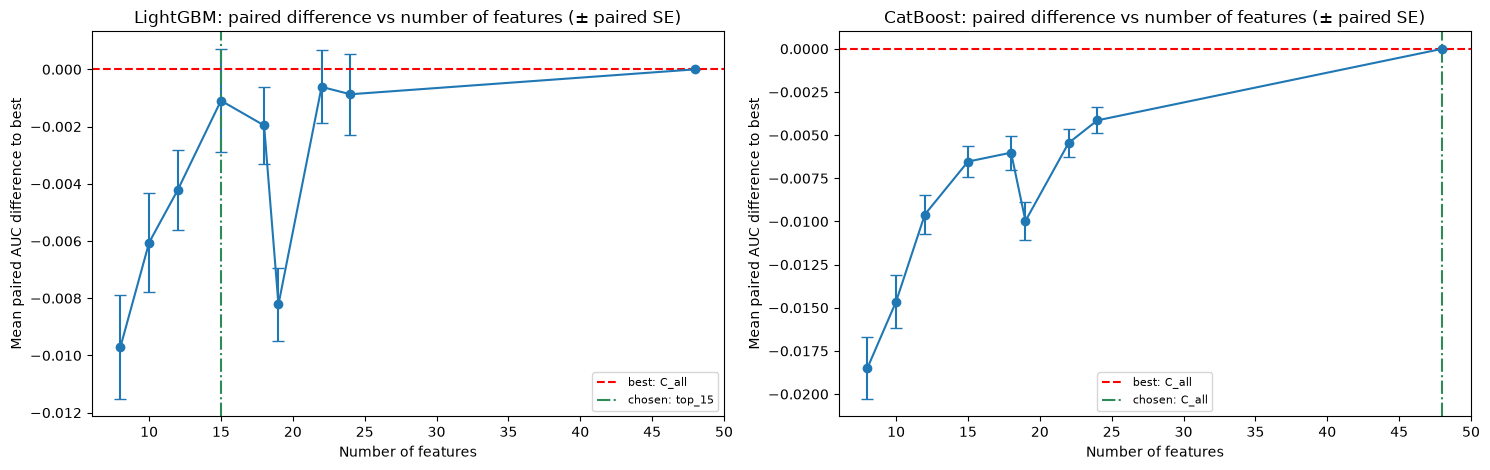

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=False)
for ax, (name, fr) in zip(axes, [('LightGBM', lgbm_sel), ('CatBoost', cat_sel)]):
    t = sorted(fr['table'], key=lambda r: r['n_features'])
    ax.errorbar([r['n_features'] for r in t], [r['diff_to_best'] for r in t],
                yerr=[r['paired_se'] for r in t], marker='o', capsize=4)
    ax.axhline(0, color='red', linestyle='--', label='best: ' + ' = '.join(fr['best_names']))
    ax.axvline(fr['chosen']['n_features'], color='seagreen', linestyle='-.',
               label='chosen: ' + ' = '.join(fr['chosen']['names']))
    ax.set_xlabel('Number of features')
    ax.set_ylabel('Mean paired AUC difference to best')
    ax.set_title(f'{name}: paired difference vs number of features (± paired SE)')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Save `selection.json`

In [10]:
def family_json(fr):
    return {
        'selection_table': fr['table'],
        'best_configuration': fr['best_names'],
        'chosen_configuration': fr['chosen']['names'],
        'chosen_features': ordered(fr['chosen']['features']),
        'importance_C_all': {c: float(v) for c, v in fr['importance_C_all'].items()},
        'importance_C_pool': {c: float(v) for c, v in fr['importance_C_pool'].items()},
        'rank_C_all': fr['rank_C_all'],
        'rank_C_pool': fr['rank_C_pool'],
    }


iv_records = []
for c in CANDIDATES:
    r = iv_table.loc[c]
    rec = {'feature': c, 'kind': r['kind'], 'iv_raw': float(r['iv_raw']), 'iv': float(r['iv']),
           'iv_es': float(r['iv_es']),
           'stability': None if pd.isna(r['stability']) else float(r['stability']),
           'stability_folds_used': int(r['stability_folds_used']), 'outcome': outcome[c]}
    if c in redundancy_drops:
        rec['redundancy_partners'] = [{'partner': p, 'spearman': rho} for p, rho in redundancy_drops[c]]
    iv_records.append(rec)

selection = {
    'strategy': STRATEGY,
    'fold_scheme': {'name': 'forward chaining (expanding window)', 'spec': FOLDS_SPEC, 'gap_days': GAP_DAYS,
                    'es_days': ES_DAYS},
    'fold_table': [{'fold': int(k), 'fit_span': r['fit'], 'es_span': r['early_stop'], 'val_span': r['validate'],
                    'fit_rows': int(r['fit_rows']), 'es_rows': int(r['es_rows']), 'val_rows': int(r['val_rows']),
                    'val_default_rate': float(r['val_default_rate'])} for k, r in fold_tbl.iterrows()],
    'overall_default_rate': float(y.mean()),
    'candidates': CANDIDATES,
    'iv_table': iv_records,
    'drops_by_step': {'floor': fail_floor, 'stability': fail_stability, 'redundancy': sorted(redundancy_drops)},
    'redundant_pairs': pairs,
    'pool': pool,
    'C_iv02': c_iv02,
    'lightgbm': family_json(lgbm_sel),
    'catboost': family_json(cat_sel),
}
(DATA / 'selection.json').write_text(json.dumps(selection, indent=2))
print('Wrote', DATA / 'selection.json')
print('LightGBM chosen:', selection['lightgbm']['chosen_configuration'], len(selection['lightgbm']['chosen_features']))
print('CatBoost chosen:', selection['catboost']['chosen_configuration'], len(selection['catboost']['chosen_features']))

Wrote ..\Data\Processed_time_cv\selection.json
LightGBM chosen: ['top_15'] 15
CatBoost chosen: ['C_all'] 48
